# Project 1 – Natural Language Inference (SNLI)

**Task:** given a _premise_ and a _hypothesis_, predict whether the premise **entails**, **contradicts** or is **neutral** towards the hypothesis.

**What we compare:**

|                     |                                                                                   |
| ------------------- | --------------------------------------------------------------------------------- |
| **Representations** | R1 token indicators · R2 bag-of-words · R3 bag-of-words + cross-sentence features |
| **Architectures**   | A1 log-linear · A2 MLP (tutorial) · A3 MLP with more regularisation               |
| **Evaluation**      | 5-fold cross-validation, accuracy, Bayesian estimation with a ROPE                |


## 0. Setup


In [1]:
import re
import sys
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

warnings.simplefilter("ignore")

# the course code (part1/) is in the same folder as this notebook
sys.path.insert(0, ".")
import part1

# the three labels, in the same order as SNLI uses them (0, 1, 2)
LABELS = part1.clslib.NamedClasses(["entailment", "neutral", "contradiction"])

SEED = 0

## 1. Data

We use SNLI. Pairs with label −1 are removed: those are pairs where the annotators did not agree on a label.

To keep the experiments fast we take a random **sample of 20,000 training pairs**. Every example is stored as `((premise, hypothesis), label)`.

- `train_pairs`: used for the tokenizer and cross-validation
- `val_pairs`: 2,000 pairs from SNLI's validation split, only used to look at how the MLP trains (section 6)
- `test_pairs`: SNLI's test split, used **once** at the very end


In [2]:
snli = load_dataset("stanfordnlp/snli")
print(snli)


def to_pairs(split):
    # turn a SNLI split into a list of ((premise, hypothesis), label)
    pairs = []
    for premise, hypothesis, label in zip(split["premise"], split["hypothesis"], split["label"]):
        if label != -1:   # -1 means the annotators did not agree, so we skip it
            pairs.append(((premise, hypothesis), label))
    return pairs


all_train = to_pairs(snli["train"])
all_val = to_pairs(snli["validation"])
test_pairs = to_pairs(snli["test"])

# take a random sample (with the same seed we get the same sample every time)
rng = np.random.default_rng(SEED)

train_order = rng.permutation(len(all_train))
train_pairs = []
for i in train_order[:50000]:
    train_pairs.append(all_train[i])

val_order = rng.permutation(len(all_val))
val_pairs = []
for i in val_order[:2000]:
    val_pairs.append(all_val[i])

print("train:", len(train_pairs), "| val:", len(val_pairs), "| test:", len(test_pairs))

# count how many pairs with label -1 were removed from each split
for split_name in ["train", "validation", "test"]:
    removed = 0
    for label in snli[split_name]["label"]:
        if label == -1:
            removed += 1
    print("removed (label -1) in the full", split_name, "split:", removed)

print("example:", train_pairs[0])

DatasetDict({
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 550152
    })
})
train: 50000 | val: 2000 | test: 9824
removed (label -1) in the full train split: 785
removed (label -1) in the full validation split: 158
removed (label -1) in the full test split: 176
example: (('A man holding a video camera standing next to a woman by water.', 'The man is holding a microphone as he introduces the woman standing by the water.'), 2)


To find out whether we can use **accuracy** as an evaluation metric, we have to check whether the classes are balanced. If one class were much bigger, a model could get a high accuracy by mostly predicting that class.


entailment 16738 -> 0.335
neutral 16458 -> 0.329
contradiction 16804 -> 0.336
majority baseline: 0.336

entailment 3329 -> 0.333
neutral 3235 -> 0.324
contradiction 3436 -> 0.344
entailment 3368 -> 0.337
neutral 3219 -> 0.322
contradiction 3413 -> 0.341


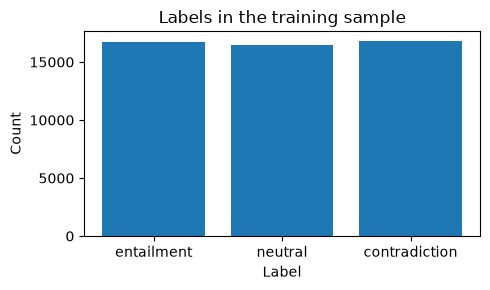

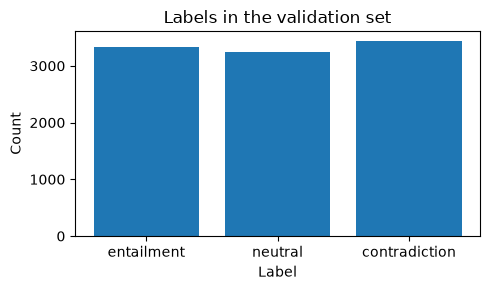

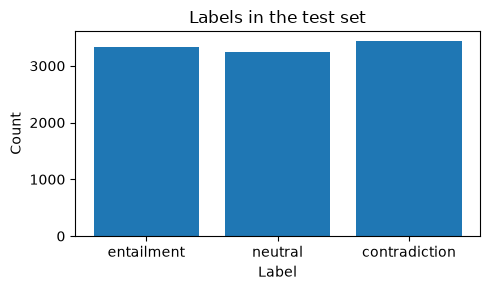

In [3]:
label_counts = Counter()
for pair, label in train_pairs:
    label_counts[LABELS.name(label)] += 1

for name in LABELS:
    print(name, label_counts[name], "->", round(label_counts[name] / len(train_pairs), 3))

plt.figure(figsize=(5, 3))
plt.bar(list(LABELS), [label_counts[name] for name in LABELS])
plt.title("Labels in the training sample")
plt.ylabel("Count")
plt.xlabel("Label")
plt.tight_layout()
plt.savefig("results/graphs/label_counts_train")

# majority baseline: the accuracy you get by always predicting the biggest class
majority = max(label_counts.values()) / len(train_pairs)
print("majority baseline:", round(majority, 3))
print()

# Counting in validation set
label_counts_val = Counter()
for ex in snli["validation"]:
    label_counts_val[LABELS.name(ex["label"])] += 1

for name in LABELS:
    print(name, label_counts_val[name], "->", round(label_counts_val[name] / len(snli["validation"]), 3))

plt.figure(figsize=(5, 3))
plt.bar(list(LABELS), [label_counts_val[name] for name in LABELS])
plt.title("Labels in the validation set")
plt.ylabel("Count")
plt.xlabel("Label")
plt.tight_layout()
plt.savefig("results/graphs/label_counts_validation")

# Counting in test set
label_counts_test = Counter()
for ex in snli["test"]:
    label_counts_test[LABELS.name(ex["label"])] += 1

for name in LABELS:
    print(name, label_counts_test[name], "->", round(label_counts_test[name] / len(snli["test"]), 3))

plt.figure(figsize=(5, 3))
plt.bar(list(LABELS), [label_counts_val[name] for name in LABELS])
plt.title("Labels in the test set")
plt.ylabel("Count")
plt.xlabel("Label")
plt.tight_layout()
plt.savefig("results/graphs/label_counts_test")


Some quick statistics that motivate the features in R3 (section 5): how long are premises and hypotheses, and how often does the hypothesis contain a negation, per label?


In [4]:
# a regular expression that finds negation words like "not", "no", "nobody", "isn't"
NEGATION = re.compile(r"\b(?:not|no|never|nobody|nothing|none|cannot)\b|n't", re.IGNORECASE)


def has_negation(sentence):
    if NEGATION.search(sentence):
        return True
    else:
        return False


rows = []
for (premise, hypothesis), label in train_pairs:
    rows.append({
        "label": LABELS.name(label),
        "premise words": len(premise.split()),
        "hypothesis words": len(hypothesis.split()),
        "negation in hypothesis": has_negation(hypothesis),
    })
stats = pd.DataFrame(rows)

# average per label
stats.groupby("label").mean().loc[list(LABELS)].round(3)

,premise words,hypothesis words,negation in hypothesis
label,,,
entailment,12.894,6.644,0.008
neutral,12.805,8.261,0.009
contradiction,12.846,7.353,0.049


## 2. Tokenizer

As in the tutorial: a BPE tokenizer with `vocab_size=1000` and `min_frequency=2`, trained with the course's `train_tokenizer`. We train it on the premises and hypotheses of the **training pairs only**, so it never sees the test data.


In [5]:
corpus = []
for ex in snli["train"]:
    premise = ex["premise"]
    hypothesis = ex["hypothesis"]
    corpus.append(premise)
    corpus.append(hypothesis)

tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size=1000, min_frequency=2)
tokenizer_500 = part1.experiment.train_tokenizer(corpus, vocab_size=500, min_frequency=2)
tokenizer_2000 = part1.experiment.train_tokenizer(corpus, vocab_size=2000, min_frequency=2)
tokenizer_4000 = part1.experiment.train_tokenizer(corpus, vocab_size=4000, min_frequency=2)
tokenizer_5000 = part1.experiment.train_tokenizer(corpus, vocab_size=5000, min_frequency=2)

from datasets import load_dataset

#Loading our training corpus
dataset = load_dataset("fancyzhx/ag_news")
corpus = dataset["train"]["text"]
tokenizer_old = part1.experiment.train_tokenizer(corpus, vocab_size=1000, min_frequency=2)

# look at one example
premise = train_pairs[0][0][0]
hypothesis = train_pairs[0][0][1]
print("premise:   ", tokenizer.encode(premise).tokens)
print("hypothesis:", tokenizer.encode(hypothesis).tokens)



















premise:    ['▁A', '▁man', '▁holding', '▁a', '▁v', 'ide', 'o', '▁camera', '▁standing', '▁next', '▁to', '▁a', '▁woman', '▁by', '▁water.']
hypothesis: ['▁The', '▁man', '▁is', '▁holding', '▁a', '▁microph', 'one', '▁as', '▁he', '▁in', 't', 'ro', 'd', 'u', 'c', 'es', '▁the', '▁woman', '▁standing', '▁by', '▁the', '▁water.']


In [6]:
# a larger resource of the same kind: ALL premises and hypotheses of SNLI's training split
# (we only use the text, not the labels, and no test data, so this is allowed)
full_corpus = []
seen_premises = set()
for premise in snli["train"]["premise"]:
    if premise not in seen_premises:      # every premise appears ~3 times, keep it once
        seen_premises.add(premise)
        full_corpus.append(premise)
for hypothesis in snli["train"]["hypothesis"]:
    full_corpus.append(hypothesis)

print("sentences in our 20k corpus:", len(corpus))
print("sentences in the full corpus:", len(full_corpus))

# we test on the validation sentences, which neither tokenizer has seen
val_sentences = []
for (premise, hypothesis), label in val_pairs:
    val_sentences.append(premise)
    val_sentences.append(hypothesis)

rows = []
for corpus_name, training_text in [("20k sample", corpus), ("full SNLI train", full_corpus)]:
    for vocab_size in [500, 1000, 2000]:
        tok = part1.experiment.train_tokenizer(training_text, vocab_size=vocab_size, min_frequency=2)
        unk_id = tok.token_to_id("[UNK]")

        total_tokens = 0
        unknown_tokens = 0
        for sentence in val_sentences:
            ids = tok.encode(sentence).ids
            total_tokens += len(ids)
            for i in ids:
                if i == unk_id:
                    unknown_tokens += 1

        rows.append({
            "trained on": corpus_name,
            "vocab size": vocab_size,
            "tokens per sentence": round(total_tokens / len(val_sentences), 2),
            "UNK rate": round(unknown_tokens / total_tokens, 5),
        })

tokenizer_comparison = pd.DataFrame(rows)
tokenizer_comparison

sentences in our 20k corpus: 120000
sentences in the full corpus: 700888




















,trained on,vocab size,tokens per sentence,UNK rate
0,20k sample,500,25.89,0.00003
1,20k sample,1000,22.64,0.00003
2,20k sample,2000,20.29,0.00004
3,full SNLI train,500,20.28,0.00000
4,full SNLI train,1000,16.50,0.00000
5,full SNLI train,2000,14.08,0.00000


## 3. Representations R1 and R2

The tutorial's encoders turn **one** text into a vector. NLI has **two** texts, and it matters which sentence a word is in ("not" in the hypothesis means something different from "not" in the premise). So we make a vector for the premise and a vector for the hypothesis **separately** and put them next to each other:

`[ premise vector (V numbers) | hypothesis vector (V numbers) ]` → 2V numbers, with V = 1000.

- **R1 – token indicators:** 1 if a token is in the sentence, 0 if not.
- **R2 – bag-of-words:** how many times each token is in the sentence.

The only difference in the code is `= 1` (R1) versus `+= 1` (R2).


In [7]:
class PairIndicator:
    # R1: for premise and hypothesis, 1 if a token is in the sentence, 0 if not

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        # premise part + hypothesis part
        return self.vocab_size * 2

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] = 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] = 1

        # put them next to each other
        return np.concatenate([premise_vector, hypothesis_vector])


class PairBagOfWords:
    # R2: same as R1 but we count how many times each token occurs

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        return self.vocab_size * 2

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] += 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] += 1

        return np.concatenate([premise_vector, hypothesis_vector])

In [8]:
R1 = PairIndicator(tokenizer)
R2 = PairBagOfWords(tokenizer)
R2_500 = PairBagOfWords(tokenizer_500)
R2_2000 = PairBagOfWords(tokenizer_2000)
R2_4000 = PairBagOfWords(tokenizer_4000)
R2_5000 = PairBagOfWords(tokenizer_5000)
R2_old = PairBagOfWords(tokenizer_old)

# test on an example
x = ("A man is playing a guitar on a stage.", "A man is not playing music.")
print("dimensions:", len(R1), len(R2))
print("sum of R1:", R1(x).sum(), "| sum of R2:", R2(x).sum())   # R2 is bigger because "a" is counted twice

dimensions: 2000 2000
sum of R1: 16.0 | sum of R2: 17.0


## 4. Cross-validation with A1 and A2

We use the course's `cross_validation_split` (5 folds) and `cross_validation_experiment`. The architectures are just settings for that function:

- **A1** – log-linear softmax regression (scikit-learn), as in the tutorial
- **A2** – one-hidden-layer MLP with the tutorial's settings

`run(name, encoder, architecture)` does the cross-validation for one system and stores the results in `my_classifiers`, in the same format as the tutorial, so the course's analysis functions work on it.

`my_seeds = [0]` gives 5 accuracies per system (one per fold).


In [9]:
A1 = {
    "model_option": "logistic",
    "loglin_args": {"max_iter": 100},
    "smlp_args": {},
}

A2 = {
    "model_option": "mlp",
    "loglin_args": {},
    "smlp_args": {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
                  "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 10},
}

num_folds = 5
my_seeds = [0]

# make the folds once, so every system uses exactly the same folds
cv_sets = {}
for seed in my_seeds:
    cv_sets[seed] = part1.experiment.cross_validation_split(train_pairs, k=num_folds, seed=seed)

my_classifiers = {}


def run(name, encoder, architecture):
    # cross-validate one system and save the results under `name`
    my_classifiers[name] = []
    all_accuracies = []

    for seed in my_seeds:
        result = part1.experiment.cross_validation_experiment(
            data_splits=cv_sets[seed],
            outcome_space=LABELS,
            encoder=encoder,
            model_option=architecture["model_option"],
            loglin_args=architecture["loglin_args"],
            smlp_args=architecture["smlp_args"],
            save_to="results/" + name + "/seed-" + str(seed),
        )
        my_classifiers[name].append(result)

        for accuracy in result["accuracies"].values():
            all_accuracies.append(accuracy)

    print(name, "mean accuracy:", round(np.mean(all_accuracies), 4), "(std", round(np.std(all_accuracies), 4), ")")

In [ ]:
# run("A1_R1", R1, A1)
# run("A1_R2", R2, A1)

  0%|          | 0/5 [00:00<?, ?it/s]

A1_R1 mean accuracy: 0.5832 (std 0.0073 )


  0%|          | 0/5 [00:00<?, ?it/s]

A1_R2 mean accuracy: 0.582 (std 0.0065 )


In [ ]:
# run("A2_R1", R1, A2)
# run("A2_R2", R2, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.690 seconds
Dataloader done! Time taken: 0.562 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0735 | train acc: 0.4423 | val loss: 1.0357 | val acc: 0.5165
Epoch 02 | train loss: 0.9858 | train acc: 0.5517 | val loss: 0.9629 | val acc: 0.5494
Epoch 03 | train loss: 0.9216 | train acc: 0.5827 | val loss: 0.9303 | val acc: 0.5675
Epoch 04 | train loss: 0.8850 | train acc: 0.6013 | val loss: 0.9152 | val acc: 0.5761
Epoch 05 | train loss: 0.8618 | train acc: 0.6123 | val loss: 0.9072 | val acc: 0.5824
Epoch 06 | train loss: 0.8448 | train acc: 0.6230 | val loss: 0.9029 | val acc: 0.5851
Epoch 07 | train loss: 0.8310 | train acc: 0.6290 | val loss: 0.8999 | val acc: 0.5884
Epoch 08 | train loss: 0.8203 | train acc: 0.6384 | val loss: 0.8984 | val acc: 0.5897
Epoch 09 | train loss: 0.8093 | train acc: 0.6422 | val loss: 0.8972 | val acc: 0.5888
Epoch 10 | train loss: 0.7986 | train acc: 0.6491 | val loss: 0.8961 | val acc: 0.5898
Training done! Time taken: 53.722 seconds
Transforming documents...
Document transformation done! Time taken: 2.001 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0720 | train acc: 0.4469 | val loss: 1.0362 | val acc: 0.5167
Epoch 02 | train loss: 0.9841 | train acc: 0.5521 | val loss: 0.9708 | val acc: 0.5480
Epoch 03 | train loss: 0.9205 | train acc: 0.5834 | val loss: 0.9419 | val acc: 0.5583
Epoch 04 | train loss: 0.8831 | train acc: 0.6028 | val loss: 0.9297 | val acc: 0.5672
Epoch 05 | train loss: 0.8587 | train acc: 0.6156 | val loss: 0.9228 | val acc: 0.5727
Epoch 06 | train loss: 0.8432 | train acc: 0.6240 | val loss: 0.9190 | val acc: 0.5749
Epoch 07 | train loss: 0.8294 | train acc: 0.6291 | val loss: 0.9175 | val acc: 0.5770
Epoch 08 | train loss: 0.8183 | train acc: 0.6366 | val loss: 0.9160 | val acc: 0.5796
Epoch 09 | train loss: 0.8076 | train acc: 0.6433 | val loss: 0.9152 | val acc: 0.5800
Epoch 10 | train loss: 0.7973 | train acc: 0.6499 | val loss: 0.9147 | val acc: 0.5810
Training done! Time taken: 47.593 seconds
Transforming documents...
Document transformation done! Time taken: 1.969 seconds
Datalo

... (14 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0731 | train acc: 0.4361 | val loss: 1.0346 | val acc: 0.5205
Epoch 02 | train loss: 0.9891 | train acc: 0.5456 | val loss: 0.9618 | val acc: 0.5594
Epoch 03 | train loss: 0.9267 | train acc: 0.5788 | val loss: 0.9254 | val acc: 0.5741
Epoch 04 | train loss: 0.8895 | train acc: 0.5988 | val loss: 0.9063 | val acc: 0.5832
Epoch 05 | train loss: 0.8650 | train acc: 0.6109 | val loss: 0.8969 | val acc: 0.5870
Epoch 06 | train loss: 0.8468 | train acc: 0.6222 | val loss: 0.8921 | val acc: 0.5902
Epoch 07 | train loss: 0.8328 | train acc: 0.6297 | val loss: 0.8884 | val acc: 0.5894
Epoch 08 | train loss: 0.8199 | train acc: 0.6387 | val loss: 0.8859 | val acc: 0.5930
Epoch 09 | train loss: 0.8088 | train acc: 0.6434 | val loss: 0.8843 | val acc: 0.5938
Epoch 10 | train loss: 0.7977 | train acc: 0.6512 | val loss: 0.8835 | val acc: 0.5957
Training done! Time taken: 47.915 seconds
Transforming documents...
Document transformation done! Time taken: 1.853 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0726 | train acc: 0.4415 | val loss: 1.0357 | val acc: 0.5149
Epoch 02 | train loss: 0.9871 | train acc: 0.5502 | val loss: 0.9670 | val acc: 0.5453
Epoch 03 | train loss: 0.9230 | train acc: 0.5829 | val loss: 0.9346 | val acc: 0.5611
Epoch 04 | train loss: 0.8860 | train acc: 0.6011 | val loss: 0.9200 | val acc: 0.5676
Epoch 05 | train loss: 0.8627 | train acc: 0.6133 | val loss: 0.9120 | val acc: 0.5722
Epoch 06 | train loss: 0.8459 | train acc: 0.6220 | val loss: 0.9080 | val acc: 0.5746
Epoch 07 | train loss: 0.8330 | train acc: 0.6280 | val loss: 0.9039 | val acc: 0.5803
Epoch 08 | train loss: 0.8216 | train acc: 0.6346 | val loss: 0.9025 | val acc: 0.5807
Epoch 09 | train loss: 0.8106 | train acc: 0.6411 | val loss: 0.9027 | val acc: 0.5795
Epoch 10 | train loss: 0.8004 | train acc: 0.6464 | val loss: 0.8995 | val acc: 0.5830
Training done! Time taken: 50.308 seconds
A2_R2 mean accuracy: 0.5876 (std 0.0054 )


In [ ]:
# run("A2_R2_500", R2_500, A2)
# run("A2_R2_2000", R2_2000, A2)
# run("A2_R2_4000", R2_4000, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.497 seconds
Dataloader done! Time taken: 0.462 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0701 | train acc: 0.4348 | val loss: 1.0380 | val acc: 0.5017
Epoch 02 | train loss: 1.0029 | train acc: 0.5268 | val loss: 0.9850 | val acc: 0.5370
Epoch 03 | train loss: 0.9553 | train acc: 0.5558 | val loss: 0.9572 | val acc: 0.5497
Epoch 04 | train loss: 0.9273 | train acc: 0.5725 | val loss: 0.9425 | val acc: 0.5594
Epoch 05 | train loss: 0.9091 | train acc: 0.5828 | val loss: 0.9346 | val acc: 0.5654
Epoch 06 | train loss: 0.8949 | train acc: 0.5912 | val loss: 0.9298 | val acc: 0.5665
Epoch 07 | train loss: 0.8835 | train acc: 0.5988 | val loss: 0.9256 | val acc: 0.5709
Epoch 08 | train loss: 0.8738 | train acc: 0.6053 | val loss: 0.9226 | val acc: 0.5738
Epoch 09 | train loss: 0.8636 | train acc: 0.6098 | val loss: 0.9193 | val acc: 0.5768
Epoch 10 | train loss: 0.8547 | train acc: 0.6165 | val loss: 0.9174 | val acc: 0.5770
Training done! Time taken: 67.607 seconds
Transforming documents...
Document transformation done! Time taken: 1.796 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0669 | train acc: 0.4451 | val loss: 1.0369 | val acc: 0.4967
Epoch 02 | train loss: 0.9999 | train acc: 0.5306 | val loss: 0.9899 | val acc: 0.5252
Epoch 03 | train loss: 0.9536 | train acc: 0.5607 | val loss: 0.9647 | val acc: 0.5384
Epoch 04 | train loss: 0.9249 | train acc: 0.5742 | val loss: 0.9527 | val acc: 0.5470
Epoch 05 | train loss: 0.9059 | train acc: 0.5867 | val loss: 0.9461 | val acc: 0.5504
Epoch 06 | train loss: 0.8935 | train acc: 0.5940 | val loss: 0.9404 | val acc: 0.5558
Epoch 07 | train loss: 0.8823 | train acc: 0.6010 | val loss: 0.9381 | val acc: 0.5561
Epoch 08 | train loss: 0.8728 | train acc: 0.6054 | val loss: 0.9345 | val acc: 0.5590
Epoch 09 | train loss: 0.8624 | train acc: 0.6114 | val loss: 0.9320 | val acc: 0.5591
Epoch 10 | train loss: 0.8541 | train acc: 0.6171 | val loss: 0.9294 | val acc: 0.5642
Training done! Time taken: 56.447 seconds
Transforming documents...
Document transformation done! Time taken: 2.064 seconds
Datalo

... (26 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0734 | train acc: 0.4638 | val loss: 1.0279 | val acc: 0.5352
Epoch 02 | train loss: 0.9663 | train acc: 0.5803 | val loss: 0.9443 | val acc: 0.5700
Epoch 03 | train loss: 0.8770 | train acc: 0.6251 | val loss: 0.9051 | val acc: 0.5926
Epoch 04 | train loss: 0.8164 | train acc: 0.6530 | val loss: 0.8876 | val acc: 0.5975
Epoch 05 | train loss: 0.7741 | train acc: 0.6733 | val loss: 0.8836 | val acc: 0.6012
Epoch 06 | train loss: 0.7412 | train acc: 0.6882 | val loss: 0.8834 | val acc: 0.6022
Epoch 07 | train loss: 0.7150 | train acc: 0.7016 | val loss: 0.8880 | val acc: 0.6012
Epoch 08 | train loss: 0.6932 | train acc: 0.7097 | val loss: 0.8943 | val acc: 0.6021
Epoch 09 | train loss: 0.6738 | train acc: 0.7197 | val loss: 0.9024 | val acc: 0.6025
Epoch 10 | train loss: 0.6570 | train acc: 0.7268 | val loss: 0.9105 | val acc: 0.5980
Training done! Time taken: 69.621 seconds
Transforming documents...
Document transformation done! Time taken: 1.935 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0712 | train acc: 0.4732 | val loss: 1.0289 | val acc: 0.5340
Epoch 02 | train loss: 0.9635 | train acc: 0.5808 | val loss: 0.9501 | val acc: 0.5640
Epoch 03 | train loss: 0.8725 | train acc: 0.6280 | val loss: 0.9159 | val acc: 0.5806
Epoch 04 | train loss: 0.8109 | train acc: 0.6558 | val loss: 0.9008 | val acc: 0.5845
Epoch 05 | train loss: 0.7678 | train acc: 0.6779 | val loss: 0.8960 | val acc: 0.5899
Epoch 06 | train loss: 0.7349 | train acc: 0.6917 | val loss: 0.8990 | val acc: 0.5911
Epoch 07 | train loss: 0.7087 | train acc: 0.7029 | val loss: 0.9043 | val acc: 0.5921
Epoch 08 | train loss: 0.6856 | train acc: 0.7142 | val loss: 0.9126 | val acc: 0.5903
Epoch 09 | train loss: 0.6666 | train acc: 0.7224 | val loss: 0.9205 | val acc: 0.5898
Epoch 10 | train loss: 0.6486 | train acc: 0.7322 | val loss: 0.9309 | val acc: 0.5877
Training done! Time taken: 77.742 seconds
A2_R2_4000 mean accuracy: 0.5919 (std 0.0062 )


In [ ]:
# run("A2_R2_5000", R2_5000, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.946 seconds
Dataloader done! Time taken: 4.684 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0712 | train acc: 0.4629 | val loss: 1.0293 | val acc: 0.5211
Epoch 02 | train loss: 0.9587 | train acc: 0.5847 | val loss: 0.9515 | val acc: 0.5597
Epoch 03 | train loss: 0.8630 | train acc: 0.6356 | val loss: 0.9163 | val acc: 0.5742
Epoch 04 | train loss: 0.7995 | train acc: 0.6659 | val loss: 0.9042 | val acc: 0.5833
Epoch 05 | train loss: 0.7521 | train acc: 0.6875 | val loss: 0.9022 | val acc: 0.5873
Epoch 06 | train loss: 0.7172 | train acc: 0.7039 | val loss: 0.9079 | val acc: 0.5876
Epoch 07 | train loss: 0.6879 | train acc: 0.7165 | val loss: 0.9169 | val acc: 0.5891
Epoch 08 | train loss: 0.6646 | train acc: 0.7265 | val loss: 0.9272 | val acc: 0.5904
Epoch 09 | train loss: 0.6420 | train acc: 0.7372 | val loss: 0.9404 | val acc: 0.5855
Epoch 10 | train loss: 0.6238 | train acc: 0.7452 | val loss: 0.9534 | val acc: 0.5844
Training done! Time taken: 68.575 seconds
Transforming documents...
Document transformation done! Time taken: 1.966 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0711 | train acc: 0.4628 | val loss: 1.0287 | val acc: 0.5329
Epoch 02 | train loss: 0.9594 | train acc: 0.5855 | val loss: 0.9540 | val acc: 0.5612
Epoch 03 | train loss: 0.8637 | train acc: 0.6360 | val loss: 0.9222 | val acc: 0.5774
Epoch 04 | train loss: 0.7982 | train acc: 0.6683 | val loss: 0.9102 | val acc: 0.5832
Epoch 05 | train loss: 0.7509 | train acc: 0.6884 | val loss: 0.9092 | val acc: 0.5854
Epoch 06 | train loss: 0.7143 | train acc: 0.7054 | val loss: 0.9152 | val acc: 0.5836
Epoch 07 | train loss: 0.6857 | train acc: 0.7162 | val loss: 0.9238 | val acc: 0.5830
Epoch 08 | train loss: 0.6607 | train acc: 0.7279 | val loss: 0.9349 | val acc: 0.5805
Epoch 09 | train loss: 0.6392 | train acc: 0.7398 | val loss: 0.9476 | val acc: 0.5812
Epoch 10 | train loss: 0.6195 | train acc: 0.7459 | val loss: 0.9618 | val acc: 0.5808
Training done! Time taken: 83.606 seconds
Transforming documents...
Document transformation done! Time taken: 1.953 seconds
Datalo

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0743 | train acc: 0.4669 | val loss: 1.0300 | val acc: 0.5408
Epoch 02 | train loss: 0.9651 | train acc: 0.5799 | val loss: 0.9450 | val acc: 0.5663
Epoch 03 | train loss: 0.8696 | train acc: 0.6294 | val loss: 0.9050 | val acc: 0.5895
Epoch 04 | train loss: 0.8039 | train acc: 0.6635 | val loss: 0.8896 | val acc: 0.5967
Epoch 05 | train loss: 0.7573 | train acc: 0.6856 | val loss: 0.8852 | val acc: 0.6021
Epoch 06 | train loss: 0.7201 | train acc: 0.7029 | val loss: 0.8888 | val acc: 0.6005
Epoch 07 | train loss: 0.6911 | train acc: 0.7138 | val loss: 0.8961 | val acc: 0.5985
Epoch 08 | train loss: 0.6657 | train acc: 0.7251 | val loss: 0.9058 | val acc: 0.5968
Epoch 09 | train loss: 0.6448 | train acc: 0.7352 | val loss: 0.9162 | val acc: 0.5961
Epoch 10 | train loss: 0.6240 | train acc: 0.7442 | val loss: 0.9277 | val acc: 0.5967
Training done! Time taken: 83.067 seconds
Transforming documents...
Document transformation done! Time taken: 1.970 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0695 | train acc: 0.4729 | val loss: 1.0237 | val acc: 0.5339
Epoch 02 | train loss: 0.9562 | train acc: 0.5873 | val loss: 0.9462 | val acc: 0.5649
Epoch 03 | train loss: 0.8630 | train acc: 0.6355 | val loss: 0.9107 | val acc: 0.5794
Epoch 04 | train loss: 0.7988 | train acc: 0.6668 | val loss: 0.8977 | val acc: 0.5853
Epoch 05 | train loss: 0.7520 | train acc: 0.6879 | val loss: 0.8958 | val acc: 0.5906
Epoch 06 | train loss: 0.7168 | train acc: 0.7028 | val loss: 0.8999 | val acc: 0.5923
Epoch 07 | train loss: 0.6869 | train acc: 0.7166 | val loss: 0.9072 | val acc: 0.5924
Epoch 08 | train loss: 0.6620 | train acc: 0.7254 | val loss: 0.9177 | val acc: 0.5906
Epoch 09 | train loss: 0.6404 | train acc: 0.7370 | val loss: 0.9301 | val acc: 0.5896
Epoch 10 | train loss: 0.6200 | train acc: 0.7477 | val loss: 0.9434 | val acc: 0.5873
Training done! Time taken: 65.816 seconds
A2_R2_5000 mean accuracy: 0.5917 (std 0.0058 )


In [ ]:
# run("A2_R2_old", R2_old, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.767 seconds
Dataloader done! Time taken: 0.565 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0725 | train acc: 0.4365 | val loss: 1.0365 | val acc: 0.5027
Epoch 02 | train loss: 0.9947 | train acc: 0.5316 | val loss: 0.9778 | val acc: 0.5325
Epoch 03 | train loss: 0.9450 | train acc: 0.5611 | val loss: 0.9548 | val acc: 0.5488
Epoch 04 | train loss: 0.9182 | train acc: 0.5756 | val loss: 0.9419 | val acc: 0.5479
Epoch 05 | train loss: 0.8996 | train acc: 0.5865 | val loss: 0.9344 | val acc: 0.5563
Epoch 06 | train loss: 0.8841 | train acc: 0.5984 | val loss: 0.9293 | val acc: 0.5603
Epoch 07 | train loss: 0.8717 | train acc: 0.6051 | val loss: 0.9258 | val acc: 0.5660
Epoch 08 | train loss: 0.8609 | train acc: 0.6112 | val loss: 0.9211 | val acc: 0.5679
Epoch 09 | train loss: 0.8485 | train acc: 0.6226 | val loss: 0.9178 | val acc: 0.5719
Epoch 10 | train loss: 0.8371 | train acc: 0.6271 | val loss: 0.9147 | val acc: 0.5742
Training done! Time taken: 43.956 seconds
Transforming documents...
Document transformation done! Time taken: 1.854 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0693 | train acc: 0.4469 | val loss: 1.0343 | val acc: 0.5123
Epoch 02 | train loss: 0.9919 | train acc: 0.5333 | val loss: 0.9797 | val acc: 0.5309
Epoch 03 | train loss: 0.9424 | train acc: 0.5624 | val loss: 0.9600 | val acc: 0.5399
Epoch 04 | train loss: 0.9148 | train acc: 0.5805 | val loss: 0.9485 | val acc: 0.5495
Epoch 05 | train loss: 0.8963 | train acc: 0.5877 | val loss: 0.9421 | val acc: 0.5539
Epoch 06 | train loss: 0.8830 | train acc: 0.5988 | val loss: 0.9381 | val acc: 0.5574
Epoch 07 | train loss: 0.8701 | train acc: 0.6075 | val loss: 0.9347 | val acc: 0.5619
Epoch 08 | train loss: 0.8584 | train acc: 0.6122 | val loss: 0.9329 | val acc: 0.5628
Epoch 09 | train loss: 0.8475 | train acc: 0.6223 | val loss: 0.9302 | val acc: 0.5678
Epoch 10 | train loss: 0.8377 | train acc: 0.6278 | val loss: 0.9270 | val acc: 0.5675
Training done! Time taken: 43.762 seconds
Transforming documents...
Document transformation done! Time taken: 1.898 seconds
Datalo

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0694 | train acc: 0.4439 | val loss: 1.0309 | val acc: 0.5132
Epoch 02 | train loss: 0.9936 | train acc: 0.5294 | val loss: 0.9722 | val acc: 0.5409
Epoch 03 | train loss: 0.9473 | train acc: 0.5563 | val loss: 0.9452 | val acc: 0.5561
Epoch 04 | train loss: 0.9215 | train acc: 0.5749 | val loss: 0.9333 | val acc: 0.5646
Epoch 05 | train loss: 0.9020 | train acc: 0.5826 | val loss: 0.9247 | val acc: 0.5675
Epoch 06 | train loss: 0.8879 | train acc: 0.5914 | val loss: 0.9166 | val acc: 0.5738
Epoch 07 | train loss: 0.8750 | train acc: 0.6011 | val loss: 0.9112 | val acc: 0.5745
Epoch 08 | train loss: 0.8638 | train acc: 0.6086 | val loss: 0.9067 | val acc: 0.5793
Epoch 09 | train loss: 0.8527 | train acc: 0.6157 | val loss: 0.9029 | val acc: 0.5806
Epoch 10 | train loss: 0.8416 | train acc: 0.6238 | val loss: 0.8991 | val acc: 0.5830
Training done! Time taken: 53.546 seconds
Transforming documents...
Document transformation done! Time taken: 1.806 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0688 | train acc: 0.4479 | val loss: 1.0301 | val acc: 0.5080
Epoch 02 | train loss: 0.9905 | train acc: 0.5357 | val loss: 0.9741 | val acc: 0.5333
Epoch 03 | train loss: 0.9447 | train acc: 0.5585 | val loss: 0.9517 | val acc: 0.5483
Epoch 04 | train loss: 0.9181 | train acc: 0.5762 | val loss: 0.9403 | val acc: 0.5558
Epoch 05 | train loss: 0.9008 | train acc: 0.5890 | val loss: 0.9325 | val acc: 0.5589
Epoch 06 | train loss: 0.8856 | train acc: 0.5966 | val loss: 0.9285 | val acc: 0.5603
Epoch 07 | train loss: 0.8733 | train acc: 0.6060 | val loss: 0.9238 | val acc: 0.5664
Epoch 08 | train loss: 0.8620 | train acc: 0.6117 | val loss: 0.9192 | val acc: 0.5725
Epoch 09 | train loss: 0.8518 | train acc: 0.6178 | val loss: 0.9160 | val acc: 0.5746
Epoch 10 | train loss: 0.8413 | train acc: 0.6264 | val loss: 0.9131 | val acc: 0.5758
Training done! Time taken: 39.323 seconds
A2_R2_old mean accuracy: 0.5762 (std 0.0054 )


         model vocab  fold       acc
0    A2_R2_500   500     0  0.575936
1    A2_R2_500   500     1  0.574410
2    A2_R2_500   500     2  0.574308
3    A2_R2_500   500     3  0.568099
4    A2_R2_500   500     4  0.575529
5        A2_R2  1000     0  0.588151
6        A2_R2  1000     1  0.585098
7        A2_R2  1000     2  0.583876
8        A2_R2  1000     3  0.587235
9        A2_R2  1000     4  0.586421
10  A2_R2_2000  2000     0  0.597007
11  A2_R2_2000  2000     1  0.593852
12  A2_R2_2000  2000     2  0.591409
13  A2_R2_2000  2000     3  0.594463
14  A2_R2_2000  2000     4  0.592732
15  A2_R2_4000  4000     0  0.595480
16  A2_R2_4000  4000     1  0.595379
17  A2_R2_4000  4000     2  0.593343
18  A2_R2_4000  4000     3  0.594768
19  A2_R2_4000  4000     4  0.597618
20  A2_R2_5000  5000     0  0.593445
21  A2_R2_5000  5000     1  0.593546
22  A2_R2_5000  5000     2  0.596295
23  A2_R2_5000  5000     3  0.596295
24  A2_R2_5000  5000     4  0.594666
25   A2_R2_old   old     0  0.576038
2

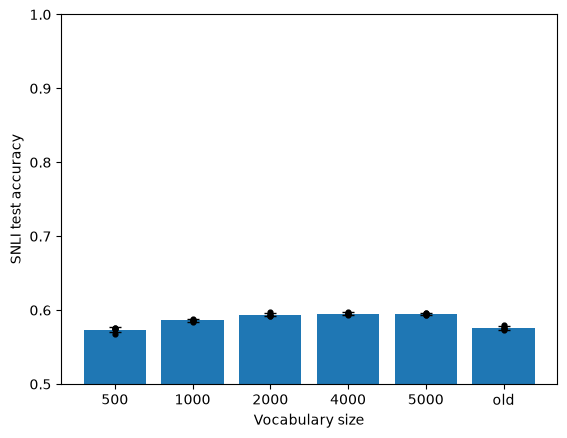

In [13]:
from sklearn.metrics import accuracy_score

X_test = [x for x, y in test_pairs]
y_test = [int(y) for x, y in test_pairs]

encs = {"A2_R2_500": R2_500, "A2_R2": R2, "A2_R2_2000": R2_2000,
        "A2_R2_4000": R2_4000, "A2_R2_5000": R2_5000, "A2_R2_old": R2_old}
labels = {"A2_R2_500": "500", "A2_R2": "1000", "A2_R2_2000": "2000",
          "A2_R2_4000": "4000", "A2_R2_5000": "5000", "A2_R2_old": "old"}  # adjust if needed

rows = []
for name, enc in encs.items():
    for fold in range(5):
        model = part1.smlp.load(f"results/{name}/seed-0/fold-{fold}/model")
        preds = part1.smlp.predict_probs(X_test, model, enc, batch_size=256).argmax(1)
        rows.append((name, labels[name], fold, accuracy_score(y_test, preds)))

df = pd.DataFrame(rows, columns=["model", "vocab", "fold", "acc"]); print(df)

m = df.groupby("vocab", sort=False).acc   # sort=False keeps your original order
plt.bar(m.mean().index, m.mean().values, yerr=m.std().values, capsize=4)
plt.scatter(df.vocab, df.acc, color="k", s=12)
plt.ylim(0.5, 1)
plt.xlabel("Vocabulary size"); plt.ylabel("SNLI test accuracy")
plt.savefig("results/graphs/different_vocabs.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Representation R3: cross-sentence features

R1 and R2 describe each sentence on its own. But NLI is about **how the two sentences relate**, and a log-linear model cannot work that out from two separate halves of a vector. R3 adds features that describe the relation directly:

| Feature                         | Idea                                                                                           |
| ------------------------------- | ---------------------------------------------------------------------------------------------- |
| **new tokens in H** (V numbers) | tokens in the hypothesis that are not in the premise → new information suggests _neutral_      |
| **overlap**                     | share of hypothesis tokens that also occur in the premise → high overlap suggests _entailment_ |
| **length difference**           | (len H − len P) / (len H + len P)                                                              |
| **negation**                    | hypothesis has a negation word and the premise does not → suggests _contradiction_             |

R3 = R2 + these features → 3V + 3 numbers. All extra features are between −1 and 1, on the same scale as the other features.


In [42]:
class PairCrossFeatures:
    # R3: R2 + features that compare the premise and the hypothesis

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        # premise part + hypothesis part + new-tokens part + 3 extra numbers
        return self.vocab_size * 3 + 3

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        # part 1 and 2: bag-of-words, the same as R2
        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] += 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] += 1

        # part 3: tokens that are in the hypothesis but NOT in the premise
        new_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            if i not in premise_ids:
                new_vector[i] = 1

        # overlap: which part of the hypothesis tokens also appears in the premise
        if len(hypothesis_ids) > 0:
            in_premise = 0
            for i in hypothesis_ids:
                if i in premise_ids:
                    in_premise += 1
            overlap = in_premise / len(hypothesis_ids)
        else:
            overlap = 0

        # length difference, scaled to be between -1 and 1
        total_length = len(hypothesis_ids) + len(premise_ids)
        if total_length > 0:
            length_difference = (len(hypothesis_ids) - len(premise_ids)) / total_length
        else:
            length_difference = 0

        # negation: 1 if the hypothesis has a negation word and the premise doesn't
        if has_negation(hypothesis) and not has_negation(premise):
            negation = 1
        else:
            negation = 0

        extra = np.array([overlap, length_difference, negation])
        return np.concatenate([premise_vector, hypothesis_vector, new_vector, extra])


R3 = PairCrossFeatures(tokenizer)
print("dimensions:", len(R3))
print("overlap, length difference, negation for the example:", R3(x)[-3:])

dimensions: 3003
overlap, length difference, negation for the example: [ 0.57142857 -0.17647059  1.        ]


In [43]:
run("A1_R3", R3, A1)
run("A2_R3", R3, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

A1_R3 mean accuracy: 0.6643 (std 0.0067 )


  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 3.483 seconds
Dataloader done! Time taken: 1.351 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0219 | train acc: 0.5228 | val loss: 0.9303 | val acc: 0.6013
Epoch 02 | train loss: 0.8610 | train acc: 0.6302 | val loss: 0.8337 | val acc: 0.6408
Epoch 03 | train loss: 0.7845 | train acc: 0.6642 | val loss: 0.8005 | val acc: 0.6540
Epoch 04 | train loss: 0.7476 | train acc: 0.6821 | val loss: 0.7871 | val acc: 0.6585
Epoch 05 | train loss: 0.7259 | train acc: 0.6911 | val loss: 0.7808 | val acc: 0.6619
Epoch 06 | train loss: 0.7108 | train acc: 0.6973 | val loss: 0.7763 | val acc: 0.6612
Epoch 07 | train loss: 0.6968 | train acc: 0.7062 | val loss: 0.7736 | val acc: 0.6636
Epoch 08 | train loss: 0.6839 | train acc: 0.7093 | val loss: 0.7737 | val acc: 0.6637
Epoch 09 | train loss: 0.6727 | train acc: 0.7157 | val loss: 0.7723 | val acc: 0.6641
Epoch 10 | train loss: 0.6629 | train acc: 0.7225 | val loss: 0.7710 | val acc: 0.6668
Training done! Time taken: 68.070 seconds
Transforming documents...
Document transformation done! Time taken: 1.762 seconds
Datalo

... (4 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0217 | train acc: 0.5274 | val loss: 0.9272 | val acc: 0.6012
Epoch 02 | train loss: 0.8624 | train acc: 0.6296 | val loss: 0.8252 | val acc: 0.6501
Epoch 03 | train loss: 0.7869 | train acc: 0.6631 | val loss: 0.7889 | val acc: 0.6621
Epoch 04 | train loss: 0.7502 | train acc: 0.6788 | val loss: 0.7743 | val acc: 0.6668
Epoch 05 | train loss: 0.7276 | train acc: 0.6907 | val loss: 0.7660 | val acc: 0.6719
Epoch 06 | train loss: 0.7109 | train acc: 0.6980 | val loss: 0.7630 | val acc: 0.6714
Epoch 07 | train loss: 0.6976 | train acc: 0.7029 | val loss: 0.7585 | val acc: 0.6768
Epoch 08 | train loss: 0.6844 | train acc: 0.7104 | val loss: 0.7566 | val acc: 0.6792
Epoch 09 | train loss: 0.6742 | train acc: 0.7137 | val loss: 0.7557 | val acc: 0.6791
Epoch 10 | train loss: 0.6627 | train acc: 0.7183 | val loss: 0.7546 | val acc: 0.6806
Training done! Time taken: 58.466 seconds
Transforming documents...
Document transformation done! Time taken: 2.523 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0207 | train acc: 0.5341 | val loss: 0.9251 | val acc: 0.6023
Epoch 02 | train loss: 0.8577 | train acc: 0.6361 | val loss: 0.8318 | val acc: 0.6321
Epoch 03 | train loss: 0.7834 | train acc: 0.6675 | val loss: 0.8014 | val acc: 0.6447
Epoch 04 | train loss: 0.7477 | train acc: 0.6820 | val loss: 0.7869 | val acc: 0.6536
Epoch 05 | train loss: 0.7250 | train acc: 0.6921 | val loss: 0.7800 | val acc: 0.6588
Epoch 06 | train loss: 0.7082 | train acc: 0.7010 | val loss: 0.7755 | val acc: 0.6593
Epoch 07 | train loss: 0.6946 | train acc: 0.7061 | val loss: 0.7746 | val acc: 0.6612
Epoch 08 | train loss: 0.6826 | train acc: 0.7123 | val loss: 0.7724 | val acc: 0.6620
Epoch 09 | train loss: 0.6717 | train acc: 0.7167 | val loss: 0.7718 | val acc: 0.6614
Epoch 10 | train loss: 0.6612 | train acc: 0.7218 | val loss: 0.7703 | val acc: 0.6629
Training done! Time taken: 54.087 seconds
A2_R3 mean accuracy: 0.6662 (std 0.0085 )


## 6. Architecture A3: a more regularised MLP

To choose a sensible change to the MLP, we first look at **how A2 trains**: we train it once on the training pairs and look at the accuracy on the separate `val_pairs` after every epoch.

- If training accuracy keeps going up while validation accuracy stops improving, the model is **overfitting** (it memorises the training data). Then we need more regularisation.
- If both stay low, the model is **underfitting**. Then we need a bigger model.


Transforming documents...
Document transformation done! Time taken: 2.088 seconds
Dataloader done! Time taken: 0.668 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0610 | train acc: 0.4550 | val loss: 1.0010 | val acc: 0.5315
Epoch 02 | train loss: 0.9638 | train acc: 0.5590 | val loss: 0.9293 | val acc: 0.5705
Epoch 03 | train loss: 0.9062 | train acc: 0.5902 | val loss: 0.9033 | val acc: 0.5900
Epoch 04 | train loss: 0.8765 | train acc: 0.6058 | val loss: 0.8922 | val acc: 0.5945
Epoch 05 | train loss: 0.8568 | train acc: 0.6160 | val loss: 0.8883 | val acc: 0.5955
Epoch 06 | train loss: 0.8414 | train acc: 0.6230 | val loss: 0.8864 | val acc: 0.5965
Epoch 07 | train loss: 0.8295 | train acc: 0.6308 | val loss: 0.8838 | val acc: 0.6010
Epoch 08 | train loss: 0.8190 | train acc: 0.6370 | val loss: 0.8832 | val acc: 0.5985
Epoch 09 | train loss: 0.8081 | train acc: 0.6422 | val loss: 0.8828 | val acc: 0.6055
Epoch 10 | train loss: 0.7988 | train acc: 0.6477 | val loss: 0.8824 | val acc: 0.6095
Training done! Time taken: 56.232 seconds


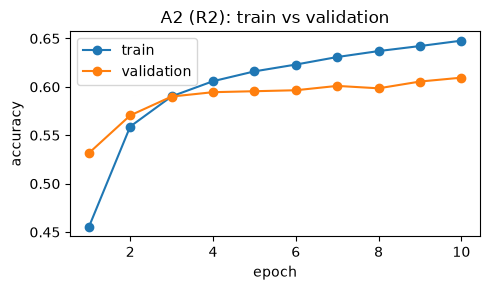

gap at the last epoch: 0.038


In [44]:
def training_curve(architecture):
    # train once on train_pairs (with R2) and return train and validation accuracy per epoch
    settings = architecture["smlp_args"]
    metrics, best_epoch, predictions = part1.smlp.train_neural_network_model(
        train_pairs, val_pairs, len(LABELS), R2, save_to="results/curve",
        hidden_dim=settings["hidden_dim"], dropout=settings["dropout"], batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        num_epochs=settings["num_epochs"],
    )
    train_accuracy = []
    val_accuracy = []
    for epoch in metrics:
        train_accuracy.append(epoch["train_metrics"]["accuracy"])
        val_accuracy.append(epoch["val_metrics"]["accuracy"])
    return train_accuracy, val_accuracy


train_acc, val_acc = training_curve(A2)

epochs = range(1, len(train_acc) + 1)
plt.figure(figsize=(5, 3))
plt.plot(epochs, train_acc, marker="o", label="train")
plt.plot(epochs, val_acc, marker="o", label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("A2 (R2): train vs validation")
plt.legend()
plt.tight_layout()
plt.show()

print("gap at the last epoch:", round(train_acc[-1] - val_acc[-1], 3))

**A3** follows from what we see: A2's validation accuracy levels off while training accuracy keeps going up, so A2 overfits. With only 20k pairs and 2,000+ input numbers, the network has many more weights than there are examples.

A3 therefore uses a **smaller hidden layer (32 instead of 128)** and **stronger dropout (0.5 instead of 0.1)**. Because this makes learning slower, it trains for **30 epochs** instead of 10. The course code keeps the epoch with the best validation loss, so extra epochs cannot hurt.


In [45]:
A3 = {
    "model_option": "mlp",
    "loglin_args": {},
    "smlp_args": {"hidden_dim": 32, "dropout": 0.5, "batch_size": 64,
                  "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 30},
}

train_acc3, val_acc3 = training_curve(A3)
print("A3 last epoch: train", round(train_acc3[-1], 3), "| validation", round(val_acc3[-1], 3),
      "| gap", round(train_acc3[-1] - val_acc3[-1], 3))

Transforming documents...
Document transformation done! Time taken: 1.948 seconds
Dataloader done! Time taken: 0.684 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0885 | train acc: 0.3922 | val loss: 1.0714 | val acc: 0.4585
Epoch 02 | train loss: 1.0504 | train acc: 0.4711 | val loss: 1.0224 | val acc: 0.5080
Epoch 03 | train loss: 1.0140 | train acc: 0.5077 | val loss: 0.9867 | val acc: 0.5360
Epoch 04 | train loss: 0.9854 | train acc: 0.5332 | val loss: 0.9614 | val acc: 0.5500
Epoch 05 | train loss: 0.9637 | train acc: 0.5492 | val loss: 0.9426 | val acc: 0.5625
Epoch 06 | train loss: 0.9440 | train acc: 0.5621 | val loss: 0.9282 | val acc: 0.5695
Epoch 07 | train loss: 0.9285 | train acc: 0.5716 | val loss: 0.9179 | val acc: 0.5725
Epoch 08 | train loss: 0.9155 | train acc: 0.5788 | val loss: 0.9094 | val acc: 0.5815
Epoch 09 | train loss: 0.9056 | train acc: 0.5862 | val loss: 0.9036 | val acc: 0.5870
Epoch 10 | train loss: 0.8964 | train acc: 0.5931 | val loss: 0.8986 | val acc: 0.5880
Epoch 11 | train loss: 0.8857 | train acc: 0.5993 | val loss: 0.8941 | val acc: 0.5910
Epoch 12 | train loss: 0.8794 | train acc: 

In [46]:
run("A3_R1", R1, A3)
run("A3_R2", R2, A3)
run("A3_R3", R3, A3)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.569 seconds
Dataloader done! Time taken: 0.565 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0925 | train acc: 0.3743 | val loss: 1.0789 | val acc: 0.4502
Epoch 02 | train loss: 1.0640 | train acc: 0.4512 | val loss: 1.0441 | val acc: 0.5033
Epoch 03 | train loss: 1.0248 | train acc: 0.5002 | val loss: 1.0078 | val acc: 0.5291
Epoch 04 | train loss: 0.9941 | train acc: 0.5281 | val loss: 0.9825 | val acc: 0.5405
Epoch 05 | train loss: 0.9718 | train acc: 0.5425 | val loss: 0.9654 | val acc: 0.5504
Epoch 06 | train loss: 0.9520 | train acc: 0.5568 | val loss: 0.9514 | val acc: 0.5625
Epoch 07 | train loss: 0.9352 | train acc: 0.5677 | val loss: 0.9401 | val acc: 0.5670
Epoch 08 | train loss: 0.9212 | train acc: 0.5758 | val loss: 0.9313 | val acc: 0.5708
Epoch 09 | train loss: 0.9133 | train acc: 0.5817 | val loss: 0.9246 | val acc: 0.5747
Epoch 10 | train loss: 0.9012 | train acc: 0.5914 | val loss: 0.9183 | val acc: 0.5774
Epoch 11 | train loss: 0.8915 | train acc: 0.5961 | val loss: 0.9133 | val acc: 0.5797
Epoch 12 | train loss: 0.8860 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0937 | train acc: 0.3689 | val loss: 1.0795 | val acc: 0.4551
Epoch 02 | train loss: 1.0639 | train acc: 0.4466 | val loss: 1.0463 | val acc: 0.5158
Epoch 03 | train loss: 1.0271 | train acc: 0.4955 | val loss: 1.0131 | val acc: 0.5336
Epoch 04 | train loss: 0.9966 | train acc: 0.5193 | val loss: 0.9888 | val acc: 0.5440
Epoch 05 | train loss: 0.9726 | train acc: 0.5410 | val loss: 0.9715 | val acc: 0.5478
Epoch 06 | train loss: 0.9522 | train acc: 0.5561 | val loss: 0.9582 | val acc: 0.5554
Epoch 07 | train loss: 0.9362 | train acc: 0.5650 | val loss: 0.9486 | val acc: 0.5612
Epoch 08 | train loss: 0.9220 | train acc: 0.5757 | val loss: 0.9408 | val acc: 0.5664
Epoch 09 | train loss: 0.9088 | train acc: 0.5861 | val loss: 0.9343 | val acc: 0.5687
Epoch 10 | train loss: 0.9005 | train acc: 0.5913 | val loss: 0.9294 | val acc: 0.5692
Epoch 11 | train loss: 0.8919 | train acc: 0.5968 | val loss: 0.9249 | val acc: 0.5705
Epoch 12 | train loss: 0.8827 | train acc: 

... (26 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0695 | train acc: 0.4266 | val loss: 1.0235 | val acc: 0.5570
Epoch 02 | train loss: 0.9914 | train acc: 0.5340 | val loss: 0.9441 | val acc: 0.6050
Epoch 03 | train loss: 0.9288 | train acc: 0.5794 | val loss: 0.8934 | val acc: 0.6296
Epoch 04 | train loss: 0.8873 | train acc: 0.6067 | val loss: 0.8584 | val acc: 0.6410
Epoch 05 | train loss: 0.8550 | train acc: 0.6243 | val loss: 0.8329 | val acc: 0.6513
Epoch 06 | train loss: 0.8326 | train acc: 0.6359 | val loss: 0.8147 | val acc: 0.6531
Epoch 07 | train loss: 0.8134 | train acc: 0.6508 | val loss: 0.8004 | val acc: 0.6576
Epoch 08 | train loss: 0.7951 | train acc: 0.6573 | val loss: 0.7893 | val acc: 0.6638
Epoch 09 | train loss: 0.7854 | train acc: 0.6624 | val loss: 0.7815 | val acc: 0.6667
Epoch 10 | train loss: 0.7731 | train acc: 0.6692 | val loss: 0.7757 | val acc: 0.6669
Epoch 11 | train loss: 0.7627 | train acc: 0.6744 | val loss: 0.7702 | val acc: 0.6696
Epoch 12 | train loss: 0.7522 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0779 | train acc: 0.4150 | val loss: 1.0381 | val acc: 0.5569
Epoch 02 | train loss: 0.9984 | train acc: 0.5431 | val loss: 0.9530 | val acc: 0.5946
Epoch 03 | train loss: 0.9345 | train acc: 0.5852 | val loss: 0.8996 | val acc: 0.6115
Epoch 04 | train loss: 0.8866 | train acc: 0.6141 | val loss: 0.8644 | val acc: 0.6266
Epoch 05 | train loss: 0.8523 | train acc: 0.6320 | val loss: 0.8396 | val acc: 0.6333
Epoch 06 | train loss: 0.8285 | train acc: 0.6413 | val loss: 0.8236 | val acc: 0.6421
Epoch 07 | train loss: 0.8086 | train acc: 0.6525 | val loss: 0.8102 | val acc: 0.6451
Epoch 08 | train loss: 0.7947 | train acc: 0.6584 | val loss: 0.8015 | val acc: 0.6505
Epoch 09 | train loss: 0.7796 | train acc: 0.6687 | val loss: 0.7938 | val acc: 0.6531
Epoch 10 | train loss: 0.7700 | train acc: 0.6718 | val loss: 0.7880 | val acc: 0.6541
Epoch 11 | train loss: 0.7589 | train acc: 0.6783 | val loss: 0.7837 | val acc: 0.6560
Epoch 12 | train loss: 0.7502 | train acc: 

## 7. Results and Bayesian analysis

First an overview of all nine systems.


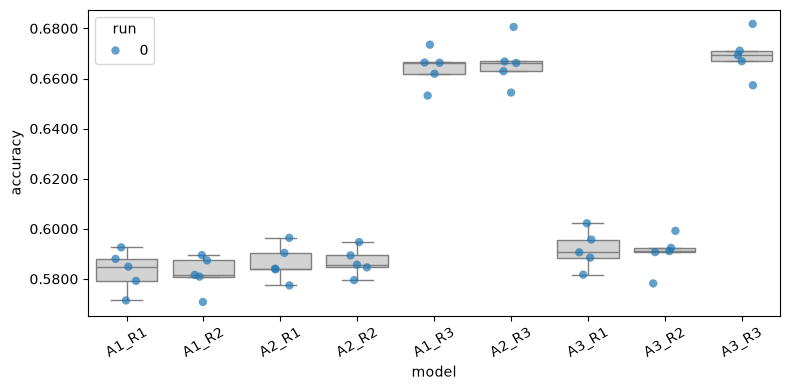

,R1,R2,R3
A1,0.5832,0.5820,0.6643
A2,0.5864,0.5868,0.6662
A3,0.5917,0.5903,0.6693


In [47]:
df_results = part1.analysis.make_data_frame(my_classifiers)
part1.analysis.plot_box_and_points(df_results)

# table: mean accuracy for every architecture (rows) and representation (columns)
table = pd.DataFrame(index=["A1", "A2", "A3"], columns=["R1", "R2", "R3"], dtype=float)
for a in ["A1", "A2", "A3"]:
    for r in ["R1", "R2", "R3"]:
        name = a + "_" + r
        table.loc[a, r] = df_results[df_results["model"] == name]["accuracy"].mean()
table.round(4)

**ROPE (region of practical equivalence).** An accuracy measured on n examples has a standard error of about √(acc·(1−acc)/n). On the ~10k test pairs that is about 0.005, so a difference smaller than about 2 standard errors (**0.01**) is within the noise of the measurement itself. We call such differences _practically equivalent_. For comparison we also report the tutorial's ROPE of 0.005.


In [48]:
acc = df_results["accuracy"].mean()
n = len(test_pairs)
standard_error = np.sqrt(acc * (1 - acc) / n)
print("standard error on the test set (n =", n, "):", round(standard_error, 4))

ROPE = 0.01

standard error on the test set (n = 9824 ): 0.0049


**Comparisons, one factor at a time.** For each pair of systems A and B, `BenavoliCorrelatedT` gives a distribution over the mean accuracy difference (B − A), taking into account that cross-validation folds overlap. We report the probability that A is better, that they are practically equivalent (difference inside the ROPE), and that B is better.

1. **Representations** (architecture fixed to A1): R1 vs R2, R2 vs R3
2. **Architectures** (representation fixed to the best one from step 1): A1 vs A2, A2 vs A3
3. **Best system vs. the tutorial default** (A1_R1)


best representation with A1: R3 | best system overall: A3_R3


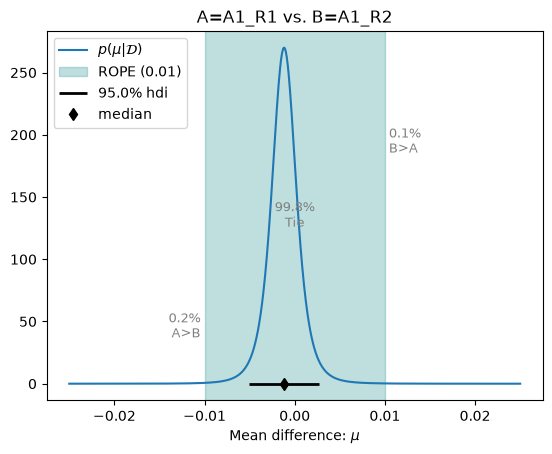

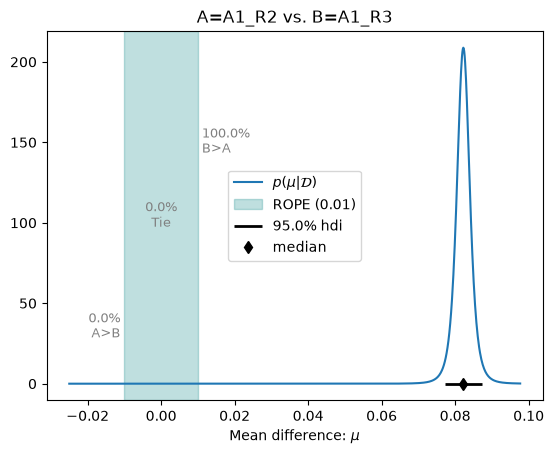

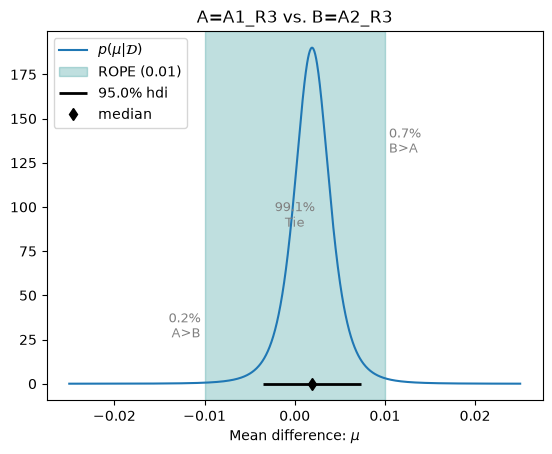

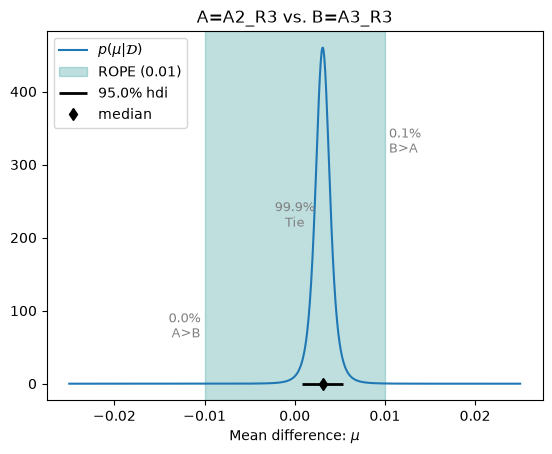

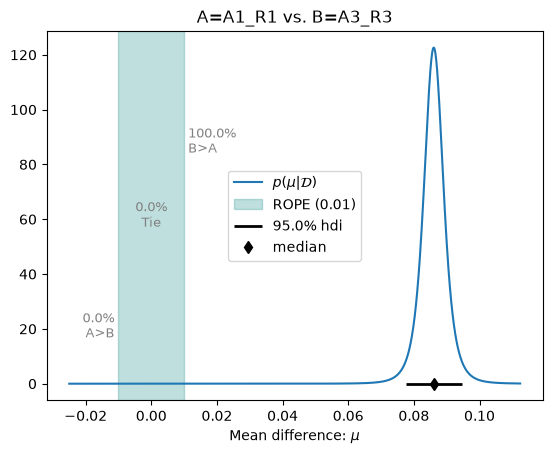

,A,B,mean diff (B-A),effect size,P(A better) 0.005,P(equivalent) 0.005,P(B better) 0.005,P(A better) 0.01,P(equivalent) 0.01,P(B better) 0.01
0,A1_R1,A1_R2,-0.001,-0.850,0.026,0.969,0.006,0.002,0.998,0.001
1,A1_R2,A1_R3,0.082,45.783,0.000,0.000,1.000,0.000,0.000,1.000
2,A1_R3,A2_R3,0.002,0.973,0.012,0.891,0.097,0.002,0.991,0.007
3,A2_R3,A3_R3,0.003,3.805,0.000,0.960,0.040,0.000,0.999,0.001
4,A1_R1,A3_R3,0.086,28.141,0.000,0.000,1.000,0.000,0.000,1.000


In [49]:
def get_accuracies(name):
    # all fold accuracies of one system, as one array
    accuracies = []
    for result in my_classifiers[name]:
        for accuracy in result["accuracies"].values():
            accuracies.append(accuracy)
    return np.array(accuracies)


def compare(a, b):
    acc_a = get_accuracies(a)
    acc_b = get_accuracies(b)

    # if the accuracies are exactly the same on every fold there is nothing to compare
    if np.allclose(acc_a, acc_b):
        print(a, "and", b, "have identical accuracies on every fold -> practically equivalent")
        return {"A": a, "B": b, "mean diff (B-A)": 0.0}

    posterior = part1.analysis.BenavoliCorrelatedT(acc_a, acc_b, runs=len(my_seeds), names=[a, b])
    row = {"A": a, "B": b, "mean diff (B-A)": posterior.mean_diff, "effect size": posterior.effect_size}

    for rope in [0.005, ROPE]:
        p_a, p_tie, p_b = posterior.probs(rope)
        row["P(A better) " + str(rope)] = p_a
        row["P(equivalent) " + str(rope)] = p_tie
        row["P(B better) " + str(rope)] = p_b

    posterior.plot(ROPE)
    plt.show()
    return row


# best representation when the architecture is A1
best_rep = "R1"
for r in ["R2", "R3"]:
    if get_accuracies("A1_" + r).mean() > get_accuracies("A1_" + best_rep).mean():
        best_rep = r

# best system overall
best_system = None
for name in my_classifiers:
    if best_system is None or get_accuracies(name).mean() > get_accuracies(best_system).mean():
        best_system = name

print("best representation with A1:", best_rep, "| best system overall:", best_system)

pairs_to_compare = [
    ("A1_R1", "A1_R2"),
    ("A1_R2", "A1_R3"),
    ("A1_" + best_rep, "A2_" + best_rep),
    ("A2_" + best_rep, "A3_" + best_rep),
]
if best_system != "A1_R1":
    pairs_to_compare.append(("A1_R1", best_system))

rows = []
for a, b in pairs_to_compare:
    rows.append(compare(a, b))
comparison = pd.DataFrame(rows)
comparison.round(3)

## 8. Test set (once)

Finally we train the best system on all 20,000 training pairs and evaluate it **once** on SNLI's test set. We report accuracy, macro-F1 and the confusion matrix, which shows which labels get confused with each other.


Transforming documents...
Document transformation done! Time taken: 2.338 seconds
Dataloader done! Time taken: 1.082 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0670 | train acc: 0.4387 | val loss: 1.0023 | val acc: 0.5630
Epoch 02 | train loss: 0.9743 | train acc: 0.5497 | val loss: 0.9064 | val acc: 0.6095
Epoch 03 | train loss: 0.9081 | train acc: 0.5976 | val loss: 0.8512 | val acc: 0.6410
Epoch 04 | train loss: 0.8648 | train acc: 0.6249 | val loss: 0.8155 | val acc: 0.6500
Epoch 05 | train loss: 0.8379 | train acc: 0.6368 | val loss: 0.7947 | val acc: 0.6635
Epoch 06 | train loss: 0.8126 | train acc: 0.6498 | val loss: 0.7773 | val acc: 0.6665
Epoch 07 | train loss: 0.7961 | train acc: 0.6592 | val loss: 0.7650 | val acc: 0.6745
Epoch 08 | train loss: 0.7826 | train acc: 0.6682 | val loss: 0.7556 | val acc: 0.6790
Epoch 09 | train loss: 0.7709 | train acc: 0.6707 | val loss: 0.7497 | val acc: 0.6800
Epoch 10 | train loss: 0.7590 | train acc: 0.6782 | val loss: 0.7448 | val acc: 0.6820
Epoch 11 | train loss: 0.7511 | train acc: 0.6813 | val loss: 0.7392 | val acc: 0.6860
Epoch 12 | train loss: 0.7447 | train acc: 

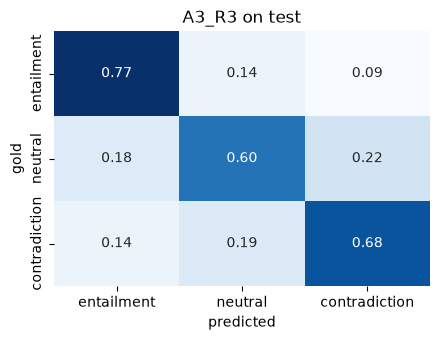

In [50]:
final = best_system
architecture_name = final.split("_")[0]
representation_name = final.split("_")[1]

if representation_name == "R1":
    encoder = R1
elif representation_name == "R2":
    encoder = R2
else:
    encoder = R3

if architecture_name == "A1":
    architecture = A1
elif architecture_name == "A2":
    architecture = A2
else:
    architecture = A3

test_texts = []
gold = []
for pair, label in test_pairs:
    test_texts.append(pair)
    gold.append(label)

if architecture["model_option"] == "logistic":
    model = part1.loglin.fit(train_pairs, encoder, max_iter=architecture["loglin_args"]["max_iter"])
    preds = part1.loglin.predict(test_texts, model, encoder)
else:
    # val_pairs is only used to pick the best epoch, the test set is only used for predicting
    settings = architecture["smlp_args"]
    part1.smlp.train_neural_network_model(
        train_pairs, val_pairs, len(LABELS), encoder, save_to="results/final_model",
        hidden_dim=settings["hidden_dim"], dropout=settings["dropout"], batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        num_epochs=settings["num_epochs"],
    )
    model = part1.smlp.load("results/final_model")
    probabilities = part1.smlp.predict_probs(test_texts, model, encoder, batch_size=256)
    preds = probabilities.argmax(axis=1)   # the label with the highest probability

print(final, "on the test set: accuracy", round(accuracy_score(gold, preds), 4),
      "| macro-F1", round(f1_score(gold, preds, average="macro"), 4))
print(classification_report(gold, preds, target_names=list(LABELS)))

cm = confusion_matrix(gold, preds, normalize="true")
plt.figure(figsize=(4.5, 3.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=list(LABELS), yticklabels=list(LABELS))
plt.xlabel("predicted")
plt.ylabel("gold")
plt.title(final + " on test")
plt.tight_layout()
plt.show()

## Conclusions

**Data**

- The labels are balanced (contradiction 34.0%, neutral 33.2%, entailment 32.9%), so **accuracy is a fair metric**. The majority baseline is **0.340**.
- Premises have the same length for every label (~12.9 words), but hypotheses differ: entailment is shortest (6.7 words), neutral longest (8.2 words). Negation occurs about 6× more often in contradiction hypotheses (4.9%) than in the others (<1%), but is rare overall.

**Tokenizer**

- With a vocabulary of 1,000, frequent words stay whole (`▁man`, `▁holding`) but rarer words are split into many small pieces (`introduces` → `▁in t ro d u c es`). A larger vocabulary might give more informative tokens.

**Representations** (all comparisons with ROPE = 0.01)

- **R1 vs R2:** 0.552 vs 0.550, P(equivalent) = 0.998 → **practically equivalent**. This is expected: in short sentences almost every token occurs only once, so counts (R2) and indicators (R1) are nearly the same vector.
- **R2 vs R3:** 0.550 → 0.626 (+0.075), P(R3 better) = 1.00 → **by far the largest effect in the project**. Features that describe the relation between premise and hypothesis help a lot.
- The gain from R3 is about the same for all three architectures (A1 +0.075, A2 +0.080, A3 +0.080). So the MLPs do **not** learn these relations by themselves from R1/R2; they need them as explicit features.

**Architectures** (on R3)

- **A1 vs A2:** 0.626 → 0.637 (+0.012), P(A2 better) = 0.74, P(equivalent) = 0.26 → the MLP is **probably slightly better**, but the difference is close to the ROPE.
- **A2 vs A3:** 0.637 → 0.640 (+0.002), P(equivalent) = 0.997 → **practically equivalent**. A2 overfits (train 0.656 vs validation 0.577 at epoch 10, gap +0.079), but the extra regularisation in A3 only reduced the gap a little (+0.070) and did not improve accuracy.
- With R1 and R2, the MLPs are only marginally better than the log-linear model (+0.005 to +0.009).

**Best system**

- **A3_R3**: CV accuracy **0.640**, test accuracy **0.654**, macro-F1 **0.650**. Compared to the tutorial default A1_R1 (0.552): +0.088, P(better) = 1.00.
- A2_R3 and A3_R3 are practically equivalent, and A1_R3 is close. In practice, **A1_R3 could be a sensible choice** too: it trains in seconds instead of minutes and its weights can be inspected.
- The test accuracy is a bit higher than the CV accuracy, probably because the final model is trained on all 20k pairs instead of 16k per fold.

**Confusion matrix**

- **Entailment** is recognised best (recall 0.76). **Neutral** is the hardest (recall 0.57): it is confused with both entailment (20%) and contradiction (23%). Contradiction is often predicted as neutral (21%).
- This makes sense: _neutral_ means the hypothesis adds information that is not in the premise, and with bag-of-words features (no word order, no meaning) that is hard to detect.

**Limitations**

- Only 20k of ~550k training pairs, one random sample and one seed (5 measurements per system).
- Bag-of-words ignores word order ("man bites dog" = "dog bites man").
- The folds are split randomly by pair, so the same premise can appear in training and validation.
- For the MLPs, the course code reports each fold's accuracy at the epoch with the best loss on that same fold, which slightly favours the MLPs.
- The best system was chosen on the CV results; A3 was designed after looking at A2 on a separate validation set.
